# Comparaison des 4 pipelines de déploiement — ResNet-18 sur CPU et GPU

Ce notebook ne fait **aucune mesure** : il rassemble les fichiers produits par les notebooks 01 à 04 (`results/*.json`, `results/*_logits.npz`), vérifie que les conditions expérimentales sont identiques, puis produit les tableaux et les graphiques du rapport (dans `figures/`).

**Avant de l'exécuter**, placer les résultats des 4 notebooks dans `results/` :
- en local : décompresser les 4 archives `*_sorties.zip` à la racine du dépôt ;
- sur Colab : soit renseigner `REPO_URL` (dépôt GitHub où les résultats ont été poussés), soit laisser vide et téléverser les 4 archives quand la cellule le demande.

Il peut s'exécuter sur un environnement CPU.

In [1]:
import os, glob, json, zipfile, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

REPO_URL = ""   # ex. "https://github.com/<utilisateur>/<depot>.git" (résultats déjà poussés dans results/)


def find_results_dir():
    for d in ("results", "../results", "/content/repo/results"):
        if glob.glob(os.path.join(d, "*_logits.npz")):
            return d
    return None


RESULTS_DIR = find_results_dir()
if RESULTS_DIR is None and REPO_URL:
    subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    RESULTS_DIR = find_results_dir()
if RESULTS_DIR is None:
    try:
        from google.colab import files
        print("Téléverser les archives *_sorties.zip produites par les notebooks 01 à 04")
        for name in files.upload():
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall(".")
        RESULTS_DIR = find_results_dir()
    except ImportError:
        pass
assert RESULTS_DIR, "Aucun résultat trouvé : placer les fichiers des notebooks 01 à 04 dans results/"
FIGURES_DIR = os.path.join(os.path.dirname(os.path.abspath(RESULTS_DIR)), "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
print("résultats :", os.path.abspath(RESULTS_DIR), "| figures :", FIGURES_DIR)

résultats : /Users/chiaramegane/Downloads/tp-deploiement-ia-pipelines/results | figures : /Users/chiaramegane/Downloads/tp-deploiement-ia-pipelines/figures


## 1. Chargement et vérification des conditions expérimentales

In [2]:
NB_NUM = {"cpu1_openvino": "01", "cpu2_torch": "02", "gpu1_tensorrt": "03", "gpu2_torch": "04"}
PIPELINES = {"cpu1_openvino": "CPU 1 · ONNX → OpenVINO", "cpu2_torch": "CPU 2 · torch.compile",
             "gpu1_tensorrt": "GPU 1 · ONNX → TensorRT", "gpu2_torch": "GPU 2 · torch.compile"}
R, L = {}, {}
for pid in PIPELINES:
    path = os.path.join(RESULTS_DIR, f"{pid}.json")
    if os.path.exists(path):
        R[pid] = json.load(open(path, encoding="utf-8"))
        L[pid] = dict(np.load(os.path.join(RESULTS_DIR, f"{pid}_logits.npz")))
    print(f"{'✔' if pid in R else '✘ manquant'}  {pid}")
assert R, "aucun fichier de résultats"


def same(key, getter):
    vals = {pid: getter(r) for pid, r in R.items()}
    ok = len({json.dumps(v, sort_keys=True) for v in vals.values()}) == 1
    print(f"{'✔' if ok else '✘'} {key:<38} {next(iter(vals.values())) if ok else vals}")
    return ok


checks = [same("mêmes images (empreinte brute)", lambda r: r["raw_images_sha"]),
          same("même tenseur prétraité (empreinte)", lambda r: r["input_sha"]),
          same("mêmes poids du modèle (empreinte)", lambda r: r["weights_sha"]),
          same("mêmes indices CIFAR-10", lambda r: r["subset_indices"]),
          same("même taille de batch / nb d'images", lambda r: (r["config"]["batch_size"], r["config"]["n_images"])),
          same("même nombre d'exécutions / de chauffe", lambda r: (r["config"]["n_runs"], r["config"]["n_warmup"]))]
if not all(checks):
    print("\n⚠️ Conditions différentes entre notebooks : à corriger (ou à justifier dans le rapport) avant d'interpréter.")
labels = np.array(next(iter(R.values()))["labels"])

✔  cpu1_openvino
✔  cpu2_torch
✔  gpu1_tensorrt
✔  gpu2_torch
✔ mêmes images (empreinte brute)         ac22f720f545b224
✔ même tenseur prétraité (empreinte)     b581e1365a579ac5
✔ mêmes poids du modèle (empreinte)      94c3ff0d5591a630
✔ mêmes indices CIFAR-10                 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 36, 37, 40, 44, 46, 48, 51, 53, 56, 61, 65, 66, 67, 70, 81]
✔ même taille de batch / nb d'images     (10, 50)
✔ même nombre d'exécutions / de chauffe  (10, 10)


In [3]:
env_rows = []
for pid, r in R.items():
    e = r["env"]
    runtime = {"cpu1_openvino": f"OpenVINO {e.get('openvino', '?')}", "gpu1_tensorrt": f"TensorRT {e.get('tensorrt', '?')}"}
    env_rows.append({"pipeline": PIPELINES[pid], "date (UTC)": e["date_utc"], "CPU": e.get("cpu_model"),
                     "vCPU / threads": f"{e['cpu_count']} / {e['torch_threads']}", "GPU": e.get("gpu", "—"),
                     "PyTorch": e["torch"], "runtime": runtime.get(pid, "PyTorch / Inductor"),
                     "CUDA": e.get("cuda", "—")})
display(pd.DataFrame(env_rows))

,pipeline,date (UTC),CPU,vCPU / threads,GPU,PyTorch,runtime,CUDA
0,CPU 1 · ONNX → OpenVINO,2026-11-20T17:25:54+00:00,arm,12 / 12,—,2.15.0,OpenVINO 2026.4.1-22982-e213a147257-releases/2...,—
1,CPU 2 · torch.compile,2026-11-20T17:26:40+00:00,arm,12 / 12,—,2.15.0,PyTorch / Inductor,—
2,GPU 1 · ONNX → TensorRT,2026-11-20T17:30:05+00:00,Intel(R) Xeon(R) CPU @ 2.00GHz,2 / 1,Tesla T4,2.14.1+cu130,TensorRT 11.5.0.63,13.0
3,GPU 2 · torch.compile,2026-11-20T17:31:38+00:00,Intel(R) Xeon(R) CPU @ 2.00GHz,2 / 1,Tesla T4,2.14.1+cu130,PyTorch / Inductor,13.0


## 2. Tableau de synthèse

Pour chaque variante : statistiques sur les exécutions (moyenne, écart-type, min, max, CV), précision et accord avec la référence, énergie, coût de préparation. **L'accélération est calculée par rapport à PyTorch eager FP32 mesuré dans le même notebook, sur le même matériel.**

In [4]:
rows = []
for pid, r in R.items():
    ref = r["variants"][r["reference_variant"]]["perf"]["throughput_img_s"]["mean"]
    for name, v in r["variants"].items():
        p, q, e, d = v["perf"], v["quality"], v["energy"], v["vs_reference"]
        rows.append({
            "pipeline_id": pid, "plateforme": r["platform"], "variante_id": name,
            "variante": f"{r['platform']} · {v['label']}" + (f" [nb {NB_NUM[pid]}]" if v["role"] == "reference" else ""),
            "rôle": v["role"], "précision": v["precision"],
            "débit_moy": p["throughput_img_s"]["mean"], "débit_std": p["throughput_img_s"]["std"],
            "débit_min": p["throughput_img_s"]["min"], "débit_max": p["throughput_img_s"]["max"],
            "débit_cv_pct": p["throughput_img_s"]["cv_pct"],
            "lat_img_moy_ms": p["latency_per_image_ms"]["mean"], "lat_img_std_ms": p["latency_per_image_ms"]["std"],
            "lat_img_min_ms": p["latency_per_image_ms"]["min"], "lat_img_max_ms": p["latency_per_image_ms"]["max"],
            "lat_batch_moy_ms": p["latency_batch_mean_ms"]["mean"], "lat_batch_std_ms": p["latency_batch_mean_ms"]["std"],
            "lat_batch_p50_ms": p["latency_batch_p50_ms"], "lat_batch_p95_ms": p["latency_batch_p95_ms"],
            "temps_50img_moy_s": p["total_s"]["mean"], "temps_50img_std_s": p["total_s"]["std"],
            "accélération": p["throughput_img_s"]["mean"] / ref,
            "top1": q["top1_accuracy"], "n_correct": q["n_correct"],
            "accord_top1_ref": d["imagenet_top1_agreement"] if d else 1.0,
            "accord_cifar_ref": d["cifar_pred_agreement"] if d else 1.0,
            "ecart_max_logits_ref": d["max_abs_diff"] if d else 0.0,
            "puissance_moy_w": e["stats"]["avg_power_w"]["mean"] if e else np.nan,
            "puissance_std_w": e["stats"]["avg_power_w"]["std"] if e else np.nan,
            "energie_mj_img_moy": 1e3 * e["stats"]["energy_per_image_j"]["mean"] if e else np.nan,
            "energie_mj_img_std": 1e3 * e["stats"]["energy_per_image_j"]["std"] if e else np.nan,
            "energie_nette_mj_img": 1e3 * e["stats"]["net_energy_per_image_j"]["mean"] if e else np.nan,
            "puissance_repos_w": e["idle_power_w"] if e else np.nan,
            "préparation_s": v["prep_time_s"], "runs": [x["throughput_img_s"] for x in v["runs"]],
        })
df = pd.DataFrame(rows)

# Vue principale : les 4 pipelines étudiés + PyTorch eager (notebooks 01 et 03) comme références CPU / GPU
MAIN_REFS = {("cpu1_openvino", "pytorch_eager"), ("gpu1_tensorrt", "pytorch_eager")}
df["principal"] = df["rôle"].eq("principal")
main = df[df["principal"] | df.apply(lambda x: (x.pipeline_id, x.variante_id) in MAIN_REFS, axis=1)].copy()
main["variante"] = main.apply(lambda x: f"{x['plateforme']} · PyTorch eager (réf.)" if x["rôle"] == "reference"
                              else f"{PIPELINES[x['pipeline_id']]}", axis=1)
main = main.sort_values(["plateforme", "principal", "pipeline_id"]).reset_index(drop=True)


def fmt_table(d):
    return pd.DataFrame({
        "variante": d["variante"], "précision": d["précision"],
        "débit (img/s)": d.apply(lambda x: f"{x['débit_moy']:.1f} ± {x['débit_std']:.1f}", axis=1),
        "min – max (img/s)": d.apply(lambda x: f"{x['débit_min']:.1f} – {x['débit_max']:.1f}", axis=1),
        "CV (%)": d["débit_cv_pct"].map(lambda v: f"{v:.1f}"),
        "latence (ms/img)": d.apply(lambda x: f"{x['lat_img_moy_ms']:.2f} ± {x['lat_img_std_ms']:.2f}", axis=1),
        "latence batch (ms)": d.apply(lambda x: f"{x['lat_batch_moy_ms']:.1f} ± {x['lat_batch_std_ms']:.1f}", axis=1),
        "accélération vs eager": d["accélération"].map(lambda v: f"×{v:.2f}"),
        "Top-1": d.apply(lambda x: f"{x['top1']:.0%} ({x['n_correct']}/50)", axis=1),
        "accord top-1 vs réf.": d["accord_top1_ref"].map(lambda v: f"{v:.0%}"),
        "énergie (mJ/img)": d.apply(lambda x: "n/d" if np.isnan(x["energie_mj_img_moy"])
                                     else f"{x['energie_mj_img_moy']:.2f} ± {x['energie_mj_img_std']:.2f}", axis=1),
        "préparation (s)": d["préparation_s"].map(lambda v: "—" if v is None or pd.isna(v) else f"{v:.1f}"),
    })


main_table = fmt_table(main)
display(main_table)
display(fmt_table(df))

df.drop(columns=["runs"]).to_csv(os.path.join(RESULTS_DIR, "tableau_complet.csv"), index=False)


def to_markdown(t):
    lines = ["| " + " | ".join(t.columns) + " |", "|" + "---|" * len(t.columns)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in t.itertuples(index=False)]
    return "\n".join(lines)


with open(os.path.join(RESULTS_DIR, "tableau_recapitulatif.md"), "w", encoding="utf-8") as f:
    f.write("## Pipelines étudiés et références\n\n" + to_markdown(main_table) +
            "\n\n## Toutes les variantes\n\n" + to_markdown(fmt_table(df)) + "\n")
print("tableaux enregistrés : results/tableau_complet.csv, results/tableau_recapitulatif.md (à coller dans le README)")

,variante,précision,débit (img/s),min – max (img/s),CV (%),latence (ms/img),latence batch (ms),accélération vs eager,Top-1,accord top-1 vs réf.,énergie (mJ/img),préparation (s)
0,CPU · PyTorch eager (réf.),FP32,133.7 ± 2.4,129.7 – 137.3,1.8,7.48 ± 0.13,74.8 ± 1.3,×1.00,54% (27/50),100%,n/d,—
1,CPU 1 · ONNX → OpenVINO,FP32,195.7 ± 3.1,190.5 – 202.2,1.6,5.11 ± 0.08,51.1 ± 0.8,×1.46,54% (27/50),100%,n/d,4.0
2,CPU 2 · torch.compile,FP32,133.0 ± 1.2,130.9 – 135.2,0.9,7.52 ± 0.07,75.2 ± 0.7,×1.02,54% (27/50),100%,n/d,12.5
3,GPU · PyTorch eager (réf.),FP32,986.7 ± 115.3,785.8 – 1063.4,11.7,1.03 ± 0.13,10.3 ± 1.3,×1.00,54% (27/50),100%,69.92 ± 0.82,—
4,GPU 1 · ONNX → TensorRT,FP32,1213.5 ± 514.4,679.8 – 1728.8,42.4,0.98 ± 0.42,9.8 ± 4.2,×1.23,54% (27/50),100%,56.27 ± 0.40,12.8
5,GPU 2 · torch.compile,FP32,826.6 ± 289.4,552.1 – 1169.9,35.0,1.35 ± 0.44,13.5 ± 4.4,×0.81,54% (27/50),100%,72.13 ± 0.22,16.8


,variante,précision,débit (img/s),min – max (img/s),CV (%),latence (ms/img),latence batch (ms),accélération vs eager,Top-1,accord top-1 vs réf.,énergie (mJ/img),préparation (s)
0,CPU · PyTorch eager (référence) [nb 01],FP32,133.7 ± 2.4,129.7 – 137.3,1.8,7.48 ± 0.13,74.8 ± 1.3,×1.00,54% (27/50),100%,n/d,—
1,CPU · ONNX Runtime (FP32),FP32,72.7 ± 1.4,70.6 – 74.7,1.9,13.77 ± 0.26,137.7 ± 2.6,×0.54,54% (27/50),100%,n/d,2.7
2,CPU · OpenVINO Runtime (FP32),FP32,195.7 ± 3.1,190.5 – 202.2,1.6,5.11 ± 0.08,51.1 ± 0.8,×1.46,54% (27/50),100%,n/d,4.0
3,CPU · PyTorch eager (référence) [nb 02],FP32,129.8 ± 7.2,120.8 – 143.5,5.5,7.73 ± 0.42,77.3 ± 4.2,×1.00,54% (27/50),100%,n/d,—
4,CPU · TorchScript (trace + freeze),FP32,133.2 ± 7.1,119.4 – 142.0,5.3,7.52 ± 0.42,75.2 ± 4.2,×1.03,54% (27/50),100%,n/d,0.8
5,"CPU · torch.compile (Inductor, FP32)",FP32,133.0 ± 1.2,130.9 – 135.2,0.9,7.52 ± 0.07,75.2 ± 0.7,×1.02,54% (27/50),100%,n/d,12.5
6,GPU · PyTorch eager (référence) [nb 03],FP32,986.7 ± 115.3,785.8 – 1063.4,11.7,1.03 ± 0.13,10.3 ± 1.3,×1.00,54% (27/50),100%,69.92 ± 0.82,—
7,GPU · TensorRT (FP32),FP32,1213.5 ± 514.4,679.8 – 1728.8,42.4,0.98 ± 0.42,9.8 ± 4.2,×1.23,54% (27/50),100%,56.27 ± 0.40,12.8
8,GPU · TensorRT (FP16),FP16,2510.3 ± 141.3,2415.7 – 2863.5,5.6,0.40 ± 0.02,4.0 ± 0.2,×2.54,54% (27/50),100%,15.59 ± 0.27,19.8
9,GPU · PyTorch eager (référence) [nb 04],FP32,1018.0 ± 114.2,814.1 – 1091.5,11.2,0.99 ± 0.12,9.9 ± 1.2,×1.00,54% (27/50),100%,70.01 ± 0.34,—


tableaux enregistrés : results/tableau_complet.csv, results/tableau_recapitulatif.md (à coller dans le README)


## 3. Graphiques

In [5]:
PIPELINE_COLORS = {"cpu1_openvino": "#2a78d6", "cpu2_torch": "#eb6834",
                   "gpu1_tensorrt": "#1baf7a", "gpu2_torch": "#eda100"}
MUTED, INK, INK2, GRID, AXIS, SURFACE = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 110})


def color_of(row):
    return PIPELINE_COLORS[row["pipeline_id"]] if row["principal"] else MUTED


def legend(fig, pids=None):
    pids = pids or [p for p in PIPELINES if p in R]
    handles = [Patch(color=PIPELINE_COLORS[p], label=PIPELINES[p]) for p in pids]
    handles.append(Patch(color=MUTED, label="référence PyTorch eager / autres variantes"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 3), fontsize=8.5,
               bbox_to_anchor=(0.5, -0.02))


def hbars(ax, d, value, err=None, fmt="{:.1f}", xlabel="", label_col="variante"):
    """Barres horizontales moyenne ± écart-type, étiquette de valeur au bout de chaque barre."""
    d = d.reset_index(drop=True)
    y = np.arange(len(d))
    vals = d[value].to_numpy(float)
    errs = d[err].to_numpy(float) if err else np.zeros(len(d))
    ax.barh(y, vals, height=0.6, color=[color_of(r) for _, r in d.iterrows()], edgecolor=SURFACE, linewidth=2)
    if err:
        ax.errorbar(vals, y, xerr=errs, fmt="none", ecolor=INK2, capsize=3, lw=1)
    top = np.nanmax(vals + np.nan_to_num(errs)) if len(d) else 1
    for yi, v, e in zip(y, vals, errs):
        if not np.isnan(v):
            txt = fmt.format(v) + (f" ± {fmt.format(e)}" if err else "")
            ax.text(v + np.nan_to_num(e) + top * 0.02, yi, txt, va="center", fontsize=8.5, color=INK)
    ax.set_yticks(y, d[label_col])
    ax.invert_yaxis()
    ax.set_xlim(0, top * 1.4)
    ax.grid(axis="x")
    ax.set_xlabel(xlabel)


def by_platform(d):
    return [(p, d[d["plateforme"] == p]) for p in ("CPU", "GPU") if (d["plateforme"] == p).any()]


def save(fig, name):
    fig.savefig(os.path.join(FIGURES_DIR, name), bbox_inches="tight")
    plt.show()

### 3.1 Débit de traitement (images/s)

CPU et GPU sont tracés sur deux axes séparés : leurs ordres de grandeur diffèrent trop pour une échelle commune (le rapport GPU/CPU est donné par le tableau).

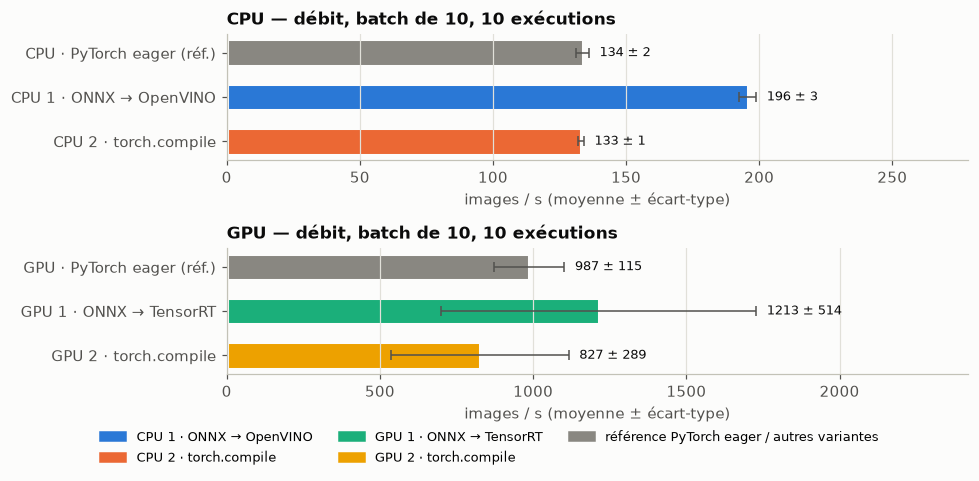

In [6]:
groups = by_platform(main)
fig, axes = plt.subplots(len(groups), 1, figsize=(9, 1.0 + 0.55 * len(main)), squeeze=False)
for ax, (plat, d) in zip(axes[:, 0], groups):
    hbars(ax, d, "débit_moy", "débit_std", "{:.0f}", "images / s (moyenne ± écart-type)")
    ax.set_title(f"{plat} — débit, batch de 10, {R[d.pipeline_id.iloc[0]]['config']['n_runs']} exécutions", loc="left")
legend(fig)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "fig1_debit.png")

### 3.2 Temps d'inférence (latence)

À gauche : temps moyen par image (temps total du passage / 50). À droite : latence d'un batch de 10 images.

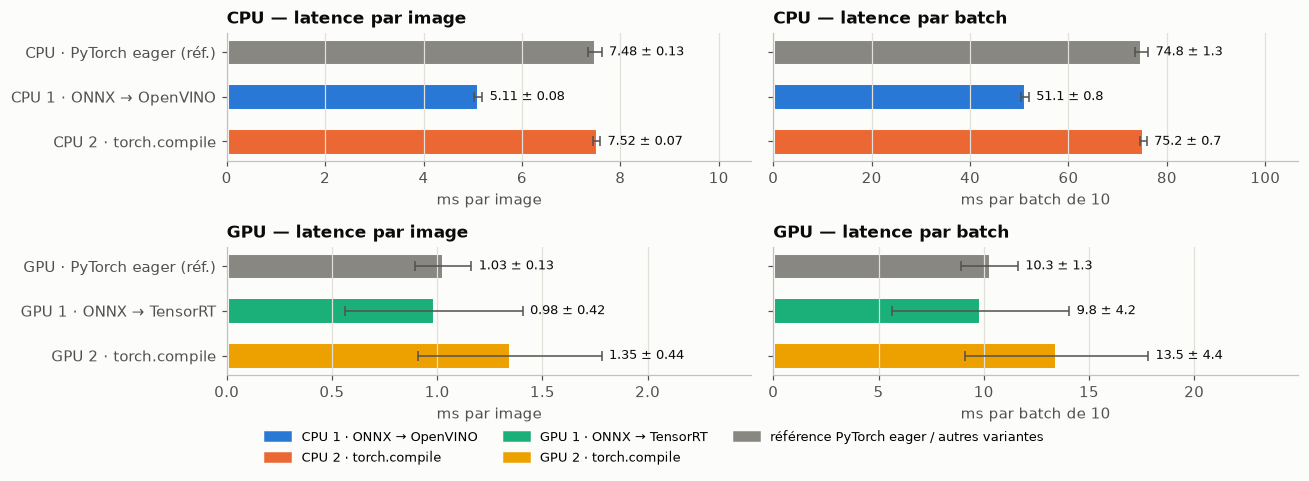

In [7]:
fig, axes = plt.subplots(len(groups), 2, figsize=(12, 1.0 + 0.55 * len(main)), squeeze=False)
for row, (plat, d) in enumerate(groups):
    hbars(axes[row, 0], d, "lat_img_moy_ms", "lat_img_std_ms", "{:.2f}", "ms par image")
    axes[row, 0].set_title(f"{plat} — latence par image", loc="left")
    hbars(axes[row, 1], d, "lat_batch_moy_ms", "lat_batch_std_ms", "{:.1f}", "ms par batch de 10")
    axes[row, 1].set_title(f"{plat} — latence par batch", loc="left")
    axes[row, 1].set_yticklabels([])
legend(fig)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "fig2_latence.png")

### 3.3 Précision Top-1 et cohérence des prédictions

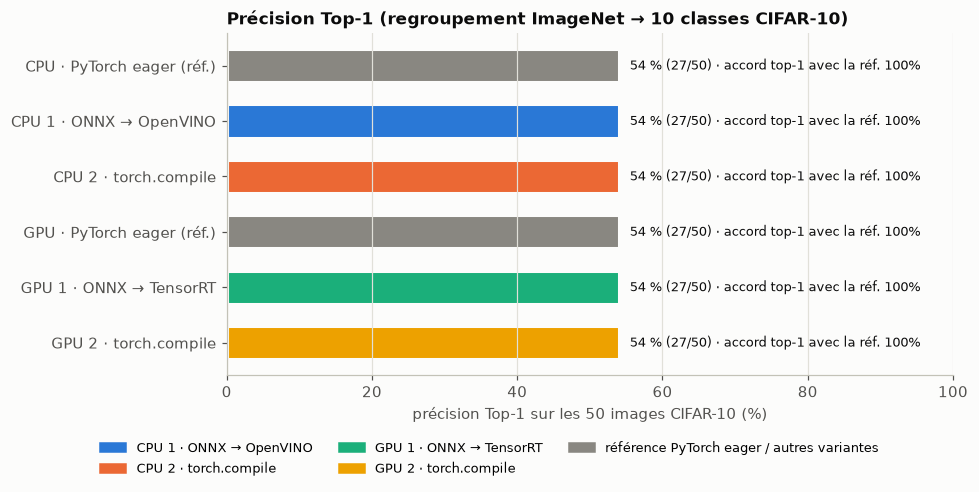

In [8]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(main) + 1.4))
d = main.assign(top1_pct=100 * main["top1"])
hbars(ax, d, "top1_pct", None, "{:.0f} %", "précision Top-1 sur les 50 images CIFAR-10 (%)")
for t in list(ax.texts):
    t.remove()
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r["top1_pct"] + 1.5, i, f"{r['top1_pct']:.0f} % ({r['n_correct']}/50) · accord top-1 avec la réf. {r['accord_top1_ref']:.0%}",
            va="center", fontsize=8.5, color=INK)
ax.set_xlim(0, 100)
ax.set_title("Précision Top-1 (regroupement ImageNet → 10 classes CIFAR-10)", loc="left")
legend(fig)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save(fig, "fig3_precision.png")

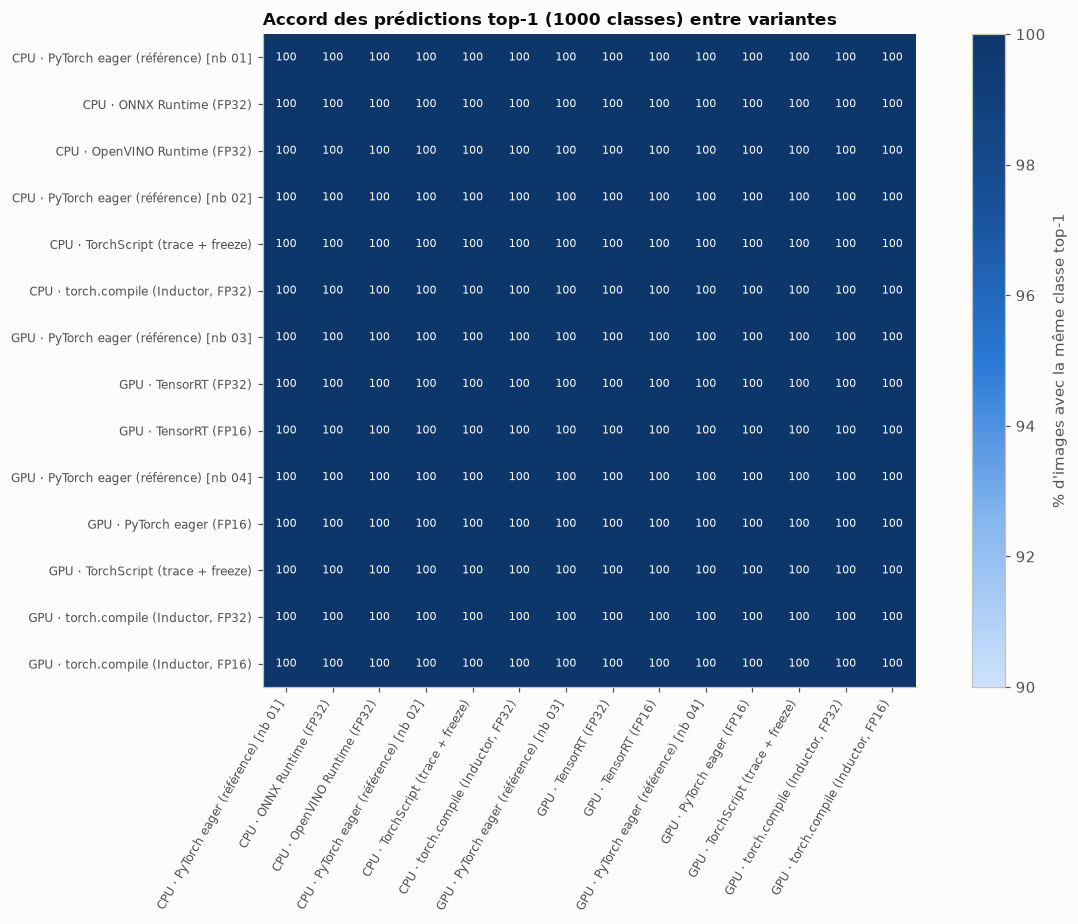

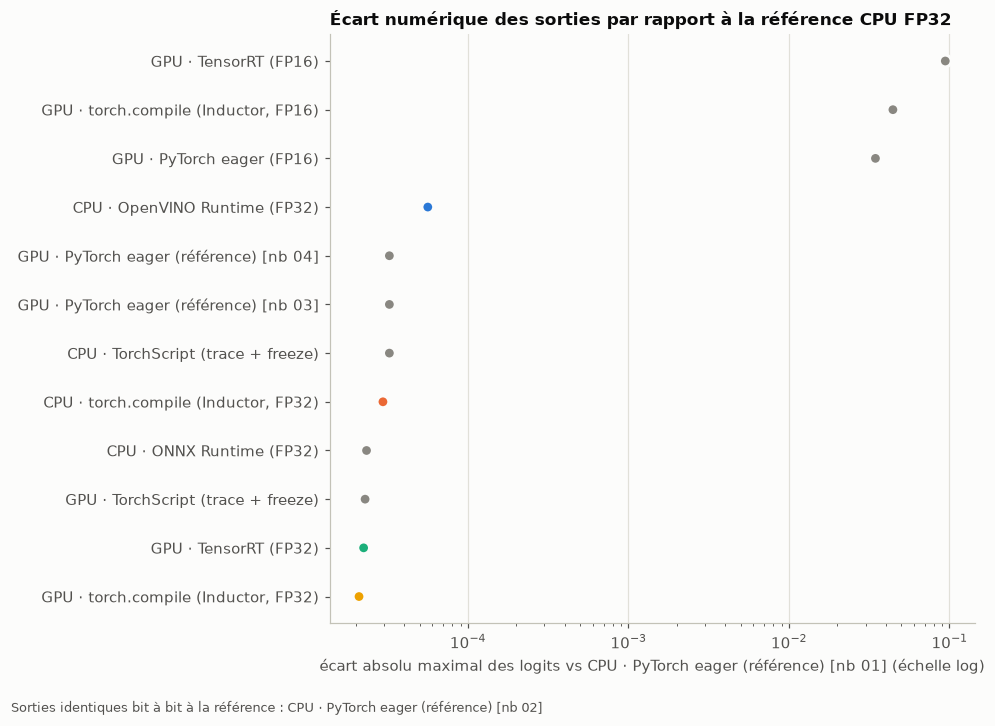

In [9]:
# Accord des prédictions entre TOUTES les variantes (top-1 ImageNet, 1000 classes) et écart des logits
keys = [(pid, v) for pid in R for v in R[pid]["variants"]]
names = [df.set_index(["pipeline_id", "variante_id"]).loc[k, "variante"] for k in keys]
top1 = np.stack([L[pid][v].argmax(1) for pid, v in keys])
agree = 100 * (top1[:, None, :] == top1[None, :, :]).mean(-1)

blues = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(0.62 * len(keys) + 3, 0.5 * len(keys) + 1.5))
vmin = min(90.0, agree.min())
im = ax.imshow(agree, cmap=blues, vmin=vmin, vmax=100)
for i in range(len(keys)):
    for j in range(len(keys)):
        ax.text(j, i, f"{agree[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if agree[i, j] > vmin + 0.6 * (100 - vmin) else INK)
ax.set_xticks(range(len(keys)), names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(keys)), names, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, label="% d'images avec la même classe top-1")
ax.set_title("Accord des prédictions top-1 (1000 classes) entre variantes", loc="left")
fig.tight_layout()
save(fig, "fig7_accord_predictions.png")

# Écart maximal des logits par rapport à la référence CPU eager FP32 (notebook 01 si disponible)
ref_key = ("cpu1_openvino", "pytorch_eager") if "cpu1_openvino" in R else keys[0]
ref = L[ref_key[0]][ref_key[1]].astype(np.float64)
diff = pd.DataFrame({"variante": names, "écart": [np.abs(L[p][v] - ref).max() for p, v in keys],
                     "principal": [R[p]["variants"][v]["role"] == "principal" for p, v in keys],
                     "pipeline_id": [p for p, _ in keys]})
diff = diff[[k != ref_key for k in keys]].sort_values("écart")
identical = diff[diff["écart"] == 0]["variante"].tolist()
diff = diff[diff["écart"] > 0]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(diff) + 1.3))
ax.scatter(diff["écart"], range(len(diff)), s=60, color=[color_of(r) for _, r in diff.iterrows()],
           edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_xscale("log")
ax.set_yticks(range(len(diff)), diff["variante"])
ax.grid(axis="x")
ax.set_xlabel(f"écart absolu maximal des logits vs {df.set_index(['pipeline_id', 'variante_id']).loc[ref_key, 'variante']} (échelle log)")
ax.set_title("Écart numérique des sorties par rapport à la référence CPU FP32", loc="left")
fig.tight_layout()
if identical:
    fig.text(0.01, -0.03, "Sorties identiques bit à bit à la référence : " + ", ".join(identical), fontsize=8.5, color=INK2)
save(fig, "fig8_ecart_logits.png")

### 3.4 Consommation énergétique

Mesurée par NVML sur GPU (énergie de la carte seule) ; sur CPU, uniquement si la VM expose Intel RAPL.

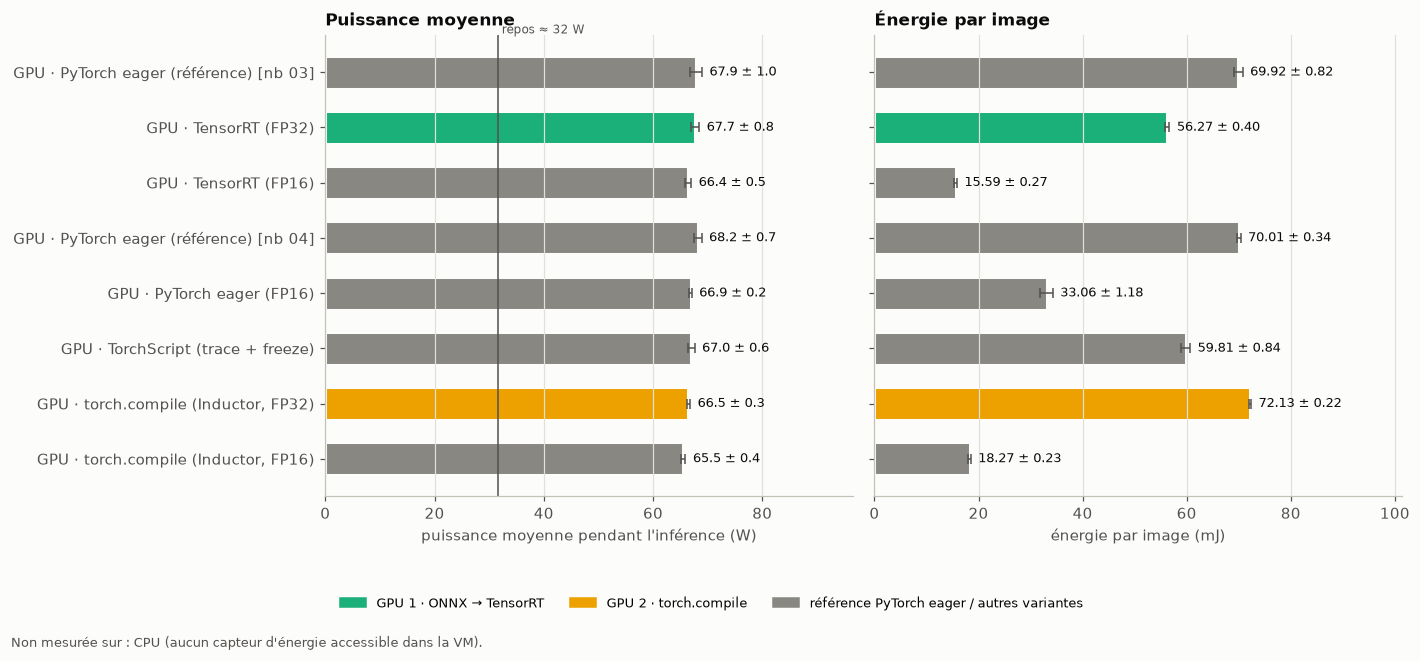

In [10]:
en = df[df["energie_mj_img_moy"].notna()]
if en.empty:
    print("Aucune mesure énergétique disponible.")
else:
    no_energy = sorted(set(df["plateforme"]) - set(en["plateforme"]))
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.5 * len(en) + 1.6))
    hbars(axes[0], en, "puissance_moy_w", "puissance_std_w", "{:.1f}", "puissance moyenne pendant l'inférence (W)")
    axes[0].set_title("Puissance moyenne", loc="left")
    idle = en["puissance_repos_w"].mean()
    axes[0].axvline(idle, color=INK2, lw=1)
    axes[0].text(idle, -0.7, f" repos ≈ {idle:.0f} W", fontsize=8, color=INK2)
    hbars(axes[1], en, "energie_mj_img_moy", "energie_mj_img_std", "{:.2f}", "énergie par image (mJ)")
    axes[1].set_title("Énergie par image", loc="left")
    axes[1].set_yticklabels([])
    legend(fig, sorted(set(en["pipeline_id"])))
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    if no_energy:
        fig.text(0.01, -0.06, f"Non mesurée sur : {', '.join(no_energy)} (aucun capteur d'énergie accessible dans la VM).",
                 fontsize=8.5, color=INK2)
    save(fig, "fig4_energie.png")

### 3.5 Variabilité et stabilité des mesures

À gauche : coefficient de variation du débit (écart-type / moyenne). À droite : écart de chaque exécution à la moyenne de sa variante (%).

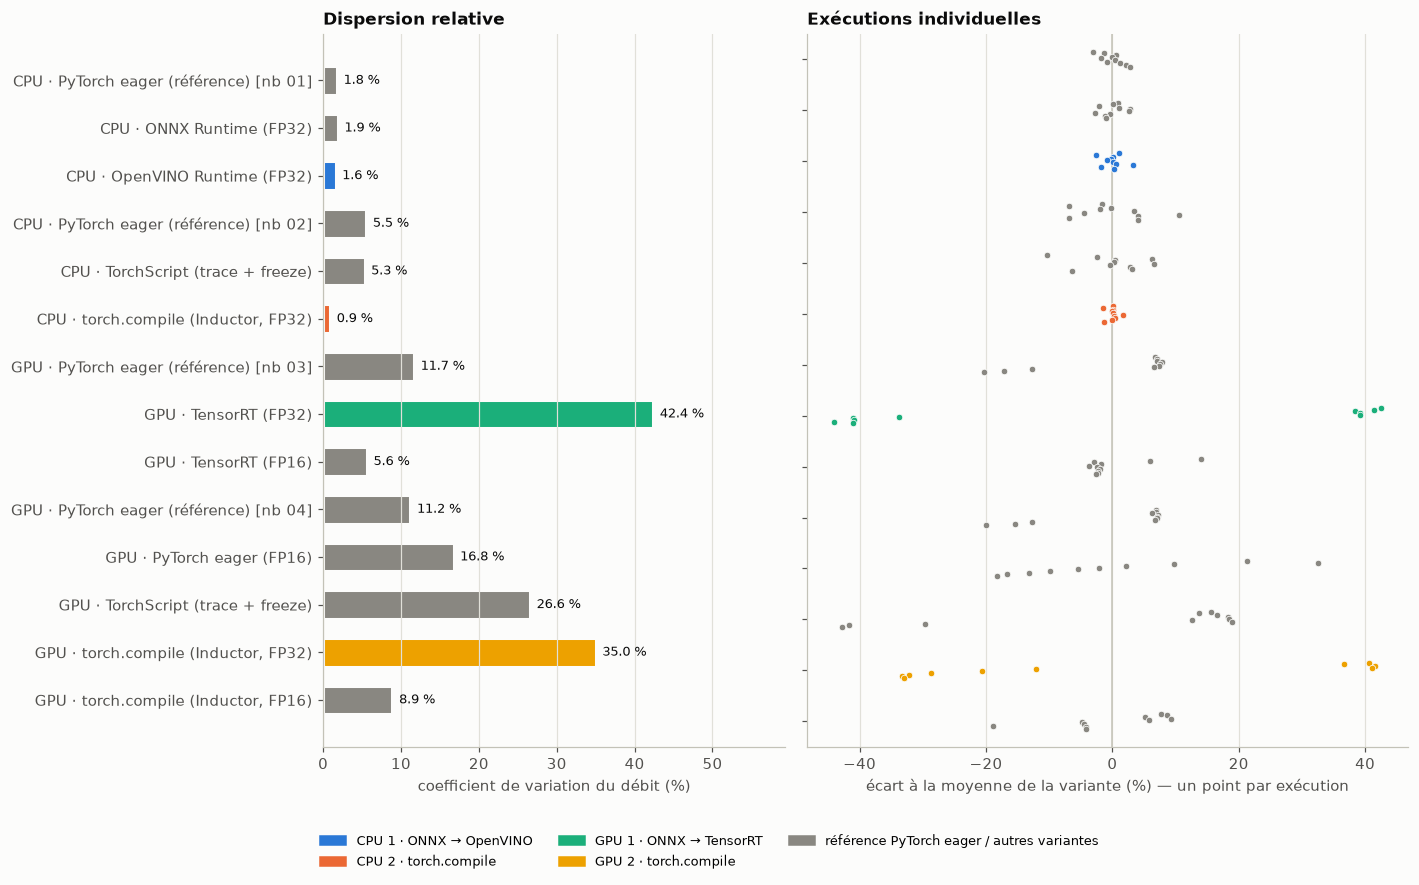

,débit eager min (img/s),débit eager max (img/s),nb de sessions,écart entre sessions (%)
plateforme,,,,
CPU,129.770950,133.667614,2,3.002724
GPU,986.652201,1018.040557,2,3.181299


In [11]:
d = df.reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(d) + 1.6), gridspec_kw={"width_ratios": [1, 1.3]})
hbars(axes[0], d, "débit_cv_pct", None, "{:.1f} %", "coefficient de variation du débit (%)")
axes[0].set_title("Dispersion relative", loc="left")
for i, (_, r) in enumerate(d.iterrows()):
    runs = np.array(r["runs"])
    dev = 100 * (runs / runs.mean() - 1)
    axes[1].scatter(dev, np.full(len(dev), i) + np.linspace(-0.15, 0.15, len(dev)), s=18,
                    color=color_of(r), edgecolor=SURFACE, linewidth=0.5, zorder=3)
axes[1].axvline(0, color=AXIS, lw=1)
axes[1].set_yticks(range(len(d)), [])
axes[1].set_ylim(len(d) - 0.5, -0.5)
axes[1].grid(axis="x")
axes[1].set_xlabel("écart à la moyenne de la variante (%) — un point par exécution")
axes[1].set_title("Exécutions individuelles", loc="left")
legend(fig)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "fig5_variabilite.png")

# Reproductibilité entre sessions : PyTorch eager est mesuré dans deux notebooks (sessions) par plateforme
rep = df[df["rôle"] == "reference"].groupby("plateforme")["débit_moy"].agg(["min", "max", "count"])
rep["écart entre sessions (%)"] = 100 * (rep["max"] / rep["min"] - 1)
display(rep.rename(columns={"min": "débit eager min (img/s)", "max": "débit eager max (img/s)",
                            "count": "nb de sessions"}))

### 3.6 Accélération par rapport à PyTorch eager (même matériel) et coût de préparation

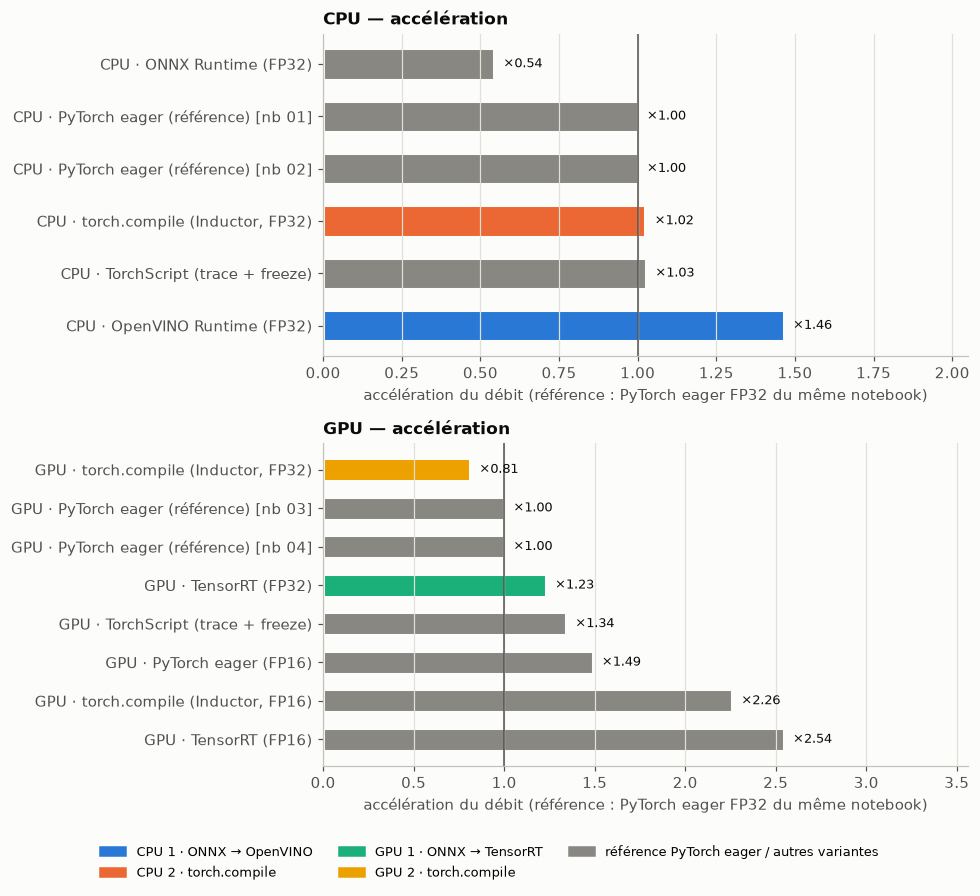

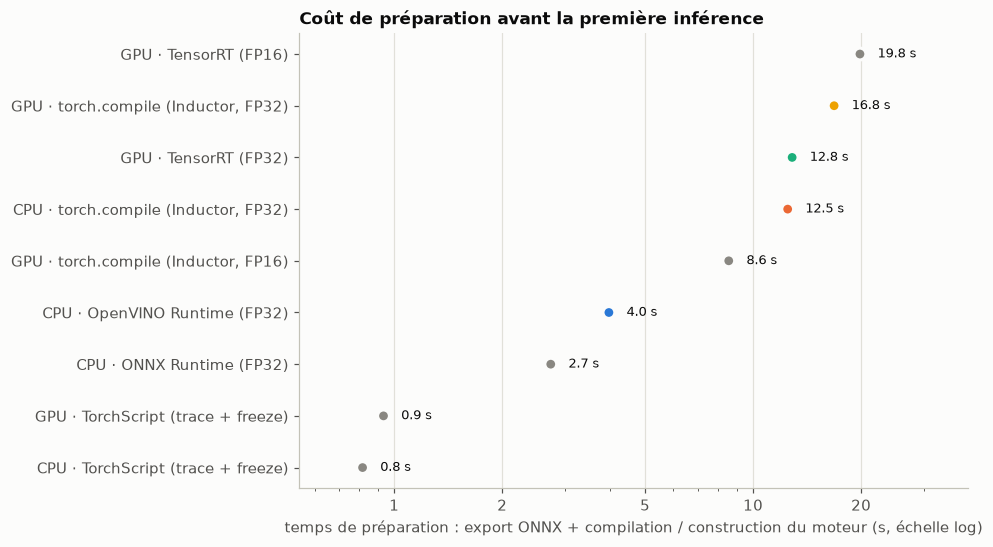

In [12]:
groups_all = by_platform(df)
fig, axes = plt.subplots(len(groups_all), 1, figsize=(9, 1.0 + 0.5 * len(df)), squeeze=False)
for ax, (plat, d) in zip(axes[:, 0], groups_all):
    d = d.sort_values("accélération")
    hbars(ax, d, "accélération", None, "×{:.2f}", "accélération du débit (référence : PyTorch eager FP32 du même notebook)")
    ax.axvline(1, color=INK2, lw=1)
    ax.set_title(f"{plat} — accélération", loc="left")
legend(fig)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "fig6_acceleration.png")

prep = df[df["préparation_s"].notna()].sort_values("préparation_s")
fig, ax = plt.subplots(figsize=(9, 0.42 * len(prep) + 1.3))
ax.scatter(prep["préparation_s"], range(len(prep)), s=60, color=[color_of(r) for _, r in prep.iterrows()],
           edgecolor=SURFACE, linewidth=2, zorder=3)
for i, v in enumerate(prep["préparation_s"]):
    ax.text(v * 1.12, i, f"{v:.1f} s", va="center", fontsize=8.5, color=INK)
ax.set_xscale("log")
ax.xaxis.set_major_locator(plt.LogLocator(base=10, subs=(1, 2, 5)))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(prep["préparation_s"].min() / 1.5, prep["préparation_s"].max() * 2)
ax.set_yticks(range(len(prep)), prep["variante"])
ax.grid(axis="x")
ax.set_xlabel("temps de préparation : export ONNX + compilation / construction du moteur (s, échelle log)")
ax.set_title("Coût de préparation avant la première inférence", loc="left")
fig.tight_layout()
save(fig, "fig9_preparation.png")

## 4. Prédictions image par image

In [13]:
CIFAR10_CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
first = next(iter(R.values()))
pred_tab = pd.DataFrame({"indice CIFAR-10": first["subset_indices"], "vraie classe": [CIFAR10_CLASSES[k] for k in labels]})
for _, r in main.iterrows():
    pred_tab[r["variante"]] = [CIFAR10_CLASSES[k] for k in R[r["pipeline_id"]]["variants"][r["variante_id"]]["quality"]["cifar_pred"]]
cols = list(pred_tab.columns[2:])
pred_tab["désaccord"] = pred_tab[cols].nunique(axis=1) > 1
pred_tab.to_csv(os.path.join(RESULTS_DIR, "predictions_par_image.csv"), index=False)
print(f"{int(pred_tab['désaccord'].sum())} image(s) sur 50 avec des prédictions différentes selon le pipeline")
display(pred_tab[pred_tab["désaccord"]] if pred_tab["désaccord"].any() else pred_tab.head(10))

per_class = pd.DataFrame({r["variante"]: R[r["pipeline_id"]]["variants"][r["variante_id"]]["quality"]["per_class_accuracy"]
                          for _, r in main.iterrows()})
display((100 * per_class).round(0).astype(int).rename_axis("précision par classe (%)"))

0 image(s) sur 50 avec des prédictions différentes selon le pipeline


,indice CIFAR-10,vraie classe,CPU · PyTorch eager (réf.),CPU 1 · ONNX → OpenVINO,CPU 2 · torch.compile,GPU · PyTorch eager (réf.),GPU 1 · ONNX → TensorRT,GPU 2 · torch.compile,désaccord
0,0,cat,dog,dog,dog,dog,dog,dog,False
1,1,ship,ship,ship,ship,ship,ship,ship,False
2,2,ship,ship,ship,ship,ship,ship,ship,False
3,3,airplane,bird,bird,bird,bird,bird,bird,False
4,4,frog,frog,frog,frog,frog,frog,frog,False
5,5,frog,dog,dog,dog,dog,dog,dog,False
6,6,automobile,truck,truck,truck,truck,truck,truck,False
7,7,frog,frog,frog,frog,frog,frog,frog,False
8,8,cat,dog,dog,dog,dog,dog,dog,False
9,9,automobile,truck,truck,truck,truck,truck,truck,False


,CPU · PyTorch eager (réf.),CPU 1 · ONNX → OpenVINO,CPU 2 · torch.compile,GPU · PyTorch eager (réf.),GPU 1 · ONNX → TensorRT,GPU 2 · torch.compile
précision par classe (%),,,,,,
airplane,20,20,20,20,20,20
automobile,20,20,20,20,20,20
bird,60,60,60,60,60,60
cat,0,0,0,0,0,0
deer,20,20,20,20,20,20
dog,100,100,100,100,100,100
frog,80,80,80,80,80,80
horse,40,40,40,40,40,40
ship,100,100,100,100,100,100


## 5. Analyse (à rédiger à partir des résultats)

Questions auxquelles le rapport doit répondre, en s'appuyant sur les figures `fig1` à `fig9` et sur `results/tableau_recapitulatif.md` :

1. **Débit et latence** — Quel pipeline est le plus rapide sur chaque plateforme ? Les écarts entre pipelines sont-ils plus grands que les écarts-types (sinon, la différence n'est pas significative) ? Quel est le rapport GPU / CPU ?
2. **Rôle des couches** — Que montre la variante de contrôle ONNX Runtime (même format, autre runtime) ? Que montrent eager FP16 vs eager FP32 (précision seule) et compilateur vs eager (optimisation seule) ? Relier aux fusions observées (nombre de nœuds ONNX → OpenVINO → TensorRT, kernels générés par Inductor).
3. **Qualité** — Top-1 identique pour toutes les variantes FP32 ? Accord des prédictions, ordre de grandeur des écarts de logits en FP32 et en FP16. Rappeler que la précision Top-1 absolue est limitée par le protocole (images 32×32 agrandies, modèle ImageNet sans réentraînement, regroupement des classes) et non par les pipelines.
4. **Énergie** — Puissance moyenne et énergie par image (GPU). Une variante plus rapide peut consommer plus de watts mais moins de joules par image : est-ce le cas ? Limites : NVML ne mesure que la carte, pas de mesure CPU sans RAPL.
5. **Stabilité et reproductibilité** — CV par variante, exécutions aberrantes, écart entre les deux mesures de PyTorch eager faites dans deux sessions différentes (même plateforme). Causes possibles : VM partagée, fréquence variable (turbo / boost GPU), température, machine Colab différente d'une session à l'autre (comparer `cpu_model` et `gpu`).
6. **Compromis** — coût de préparation (compilation / construction du moteur) vs gain par image, portabilité (un moteur TensorRT est lié au GPU), simplicité d'intégration (torch.compile reste dans PyTorch).